In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.ticker as plticke



In [18]:
#Chargement des données propres
df = pd.read_csv('../dataset/traite/train_cleaned.csv')

In [19]:
# Vérification des types de données de chaque colonne
df.dtypes

Order                       int64
MS SubClass                 int64
Lot Frontage              float64
Lot Area                    int64
Street                      int64
Alley                       int64
Lot Shape                   int64
Land Slope                  int64
Overall Qual                int64
Overall Cond                int64
Year Built                  int64
Year Remod/Add              int64
Mas Vnr Area              float64
Exter Qual                  int64
Exter Cond                  int64
Bsmt Qual                   int64
Bsmt Cond                   int64
Bsmt Exposure               int64
BsmtFin Type 1              int64
BsmtFin SF 1              float64
BsmtFin Type 2              int64
BsmtFin SF 2              float64
Bsmt Unf SF               float64
Total Bsmt SF             float64
Heating QC                  int64
Central Air                 int64
1st Flr SF                  int64
2nd Flr SF                  int64
Low Qual Fin SF             int64
Gr Liv Area   

Les données du dataset sont majoritairement composées de variables numériques de type int64 et float64, représentant des caractéristiques quantitatives des biens immobiliers. On observe également la présence de variables booléennes (bool), issues de l’encodage des variables catégorielles (One-Hot Encoding).

Cette structure rend le dataset directement exploitable par les modèles de régression linéaire avec régularisation (Ridge), Random Forest et XGBoost, qui nécessitent des entrées numériques. Les variables booléennes sont automatiquement interprétées comme des valeurs binaires (0/1), ce qui est compatible avec ces algorithmes.

Ainsi, aucune transformation supplémentaire des types de données n’est requise avant l’entraînement des modèles, ce qui permet de se concentrer sur l’évaluation et l’optimisation des performances prédictives.

Dans cette étape, nous séparons la variable cible SalePrice, qui correspond au prix de vente que nous souhaitons prédire, des variables explicatives X qui représentent les caractéristiques descriptives des biens immobiliers. Cette séparation est essentielle car les modèles de machine learning tels que: "la régression Ridge, le Random Forest et XGBoost" apprennent à partir des caractéristiques d’entrée (X) pour estimer la variable cible (y).

Cela permet d’entraîner les modèles en leur fournissant clairement les données d’entrée et la sortie attendue, facilitant ainsi la construction d’un modèle capable de faire des prédictions précises sur de nouvelles données.

In [20]:
# Séparation Features (X) / Target (y)
y = df['SalePrice']
X = df.drop('SalePrice', axis=1)

Afin d’évaluer la performance réelle de nos modèles prédictifs, nous utilisons une technique appelée validation croisée par K-fold. Cette méthode consiste à diviser le jeu de données en plusieurs sous-ensembles (ici 5 folds), puis à entraîner le modèle sur 4 folds tout en testant ses performances sur le fold restant. Ce processus est répété pour chaque fold, ce qui permet d’obtenir une estimation plus fiable et robuste de la performance du modèle, en limitant les risques de sur-apprentissage (overfitting) ou de biais liés à un découpage particulier des données.

Pour éviter que l’ordre initial des données n’influence la division, nous mélangeons les observations avant de les répartir. De plus, en fixant une graine aléatoire, nous garantissons la reproductibilité des résultats.

Comme métrique d’évaluation, nous utilisons la racine de l’erreur quadratique moyenne (RMSE), qui mesure en moyenne la distance entre les prédictions et les valeurs réelles. Une RMSE faible indique un bon ajustement du modèle aux données. Cette métrique est particulièrement adaptée aux problèmes de régression comme la prédiction du prix de vente immobilier.



In [21]:
# Définition de la méthode de validation (Cross-Validation)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Fonction pour calculer la RMSE moyenne en validation croisée
# cross_val_score effectue l'entraînement et la validation du modèle sur chaque fold
# scoring="neg_mean_squared_error" utilise l'erreur quadratique moyenne négative (pour sklearn, le score doit être maximisé)
# on applique np.sqrt et on inverse le signe pour obtenir la RMSE (Root Mean Squared Error)
# La RMSE mesure l'écart moyen entre les prédictions du modèle et les valeurs réelles
# Plus la RMSE est faible, meilleure est la qualité prédictive du modèle

def cv_rmse(model):
    rmse = np.sqrt(-cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=kf))
    return rmse

In [22]:
# Modèle 1

#A)Régression Linéaire Multiple Standard (Sans filet de sécurité)
lr_model = LinearRegression()

score_lr = cv_rmse(lr_model)
print(f"Linear Regression (OLS) Score: {score_lr.mean():.4f} (std: {score_lr.std():.4f})")


Linear Regression (OLS) Score: 0.1243 (std: 0.0167)


In [23]:
# Modèle 1 

#B) Régression Linéaire (Ridge) avec régularisation alpha=10,
# ce qui aide à réduire le sur-apprentissage en limitant la taille des coefficients.
ridge_model = Ridge(alpha=10)

score_ridge = cv_rmse(ridge_model)

# Affichage de la RMSE moyenne et de son écart-type pour juger précision et stabilité du modèle.
print(f"Ridge (Linear) Score: {score_ridge.mean():.4f} (std: {score_ridge.std():.4f})")


Ridge (Linear) Score: 0.1152 (std: 0.0171)


In [24]:
# Modèle 2 : Random Forest 

# n_estimators = 100 signifie que la forêt contient 100 arbres de décision,
# ce qui est un bon compromis entre précision et temps de calcul.
# random_state=42 garantit la reproductibilité des résultats.
# n_jobs=-1 permet d'utiliser tous les cœurs CPU pour accélérer l'entraînement.rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

score_rf = cv_rmse(rf_model)
print(f"Random Forest Score: {score_rf.mean():.4f} (std: {score_rf.std():.4f})")


Random Forest Score: 0.1327 (std: 0.0149)


In [25]:
import xgboost as xgb

# Modèle 3 : XGBoost

#  XGBoost est un algorithme de boosting basé sur des arbres de décision,
# qui construit les arbres de manière séquentielle pour corriger les erreurs des arbres précédents.

xgb_model = xgb.XGBRegressor(
       objective='reg:squarederror',  # Fonction objectif : minimiser l'erreur quadratique
    n_estimators=1000,                # Nombre d'arbres élevé pour une bonne performance
    learning_rate=0.05,               # Taux d'apprentissage faible, apprentissage progressif pour éviter le sur-apprentissage
    max_depth=3,                      # Profondeur limitée des arbres pour contrôler la complexité et éviter l'overfitting
    colsample_bytree=0.7,             # Utilisation de 70% des colonnes à chaque arbre pour plus de diversité
    random_state=42,                  # Graine aléatoire pour reproductibilité
    n_jobs=-1                         # Utilisation de tous les cœurs CPU pour accélérer l'entraînement
)

print("Entraînement XGBoost en cours... (patience)")
score_xgb = cv_rmse(xgb_model)
print(f"XGBoost Score: {score_xgb.mean():.4f} (std: {score_xgb.std():.4f})")


Entraînement XGBoost en cours... (patience)
XGBoost Score: 0.1124 (std: 0.0153)


Parmi les quatre modèles testés pour prédire le prix des logements, XGBoost arrive en tête avec une erreur moyenne de 11,24 % seulement. Il est suivi de près par la régression Ridge (11,52 % d’erreur), qui reste très performante tout en étant plus simple et rapide à interpréter. La régression linéaire classique obtient une erreur de 12,43 %, tandis que le Random Forest se situe en dernière position avec 13,27 % d’erreur.

In [26]:
import pandas as pd
from tabulate import tabulate

# Étape 1: Comparaison des modèles par validation croisée
print("Comparaison des modèles par validation croisée...")


# Calcul des scores RMSE pour chaque modèle
score_lr = cv_rmse(lr_model)
score_rf = cv_rmse(rf_model)
score_xgb = cv_rmse(xgb_model)
score_ridge = cv_rmse(ridge_model)  


# Identifier le meilleur modèle parmi les 4
scores = {
    "Linear Regression": score_lr.mean(),
    "Random Forest": score_rf.mean(),
    "XGBoost": score_xgb.mean(),
    "Ridge": score_ridge.mean()
}

best_model_name = min(scores, key=scores.get)
best_score = scores[best_model_name]

print(f"\n Le meilleur modèle est: {best_model_name} avec un RMSE moyen de {best_score:.4f}")

# Affichage des résultats dans un tableau (avec les scores dynamiques)
print("\n")
print("RÉSULTATS DES MODÈLES (validation croisée)")


results = pd.DataFrame({
    'Modèle': ['Linear Regression', 'Random Forest', 'XGBoost', 'Ridge'],
    'RMSE moyen': [score_lr.mean(), score_rf.mean(), score_xgb.mean(), score_ridge.mean()],
    'Écart-type': [score_lr.std(), score_rf.std(), score_xgb.std(), score_ridge.std()],
    'RMSE min': [score_lr.min(), score_rf.min(), score_xgb.min(), score_ridge.min()],
    'RMSE max': [score_lr.max(), score_rf.max(), score_xgb.max(), score_ridge.max()]
})


# Trier par RMSE moyen (du meilleur au pire)
results = results.sort_values('RMSE moyen')

print(tabulate(results, headers='keys', tablefmt='fancy_grid', floatfmt=".4f"))



Comparaison des modèles par validation croisée...

 Le meilleur modèle est: XGBoost avec un RMSE moyen de 0.1124


RÉSULTATS DES MODÈLES (validation croisée)
╒════╤═══════════════════╤══════════════╤══════════════╤════════════╤════════════╕
│    │ Modèle            │   RMSE moyen │   Écart-type │   RMSE min │   RMSE max │
╞════╪═══════════════════╪══════════════╪══════════════╪════════════╪════════════╡
│  2 │ XGBoost           │       0.1124 │       0.0153 │     0.0915 │     0.1312 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  3 │ Ridge             │       0.1152 │       0.0171 │     0.0899 │     0.1353 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  0 │ Linear Regression │       0.1243 │       0.0167 │     0.0927 │     0.1386 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  1 │ Random Forest     │       0.1327 │       0.0149 │     0.1112 │     0.1502 │
╘════╧══════

La métrique retenue pour la comparaison est le RMSE (Root Mean Squared Error), car elle pénalise fortement les grandes erreurs de prédiction et est particulièrement adaptée aux problèmes de régression liés aux prix immobiliers.
Un RMSE faible indique une meilleure capacité du modèle à prédire avec précision les prix réels.

Les résultats montrent que le modèle XGBoost obtient le RMSE moyen le plus faible (0.1124), ce qui indique de meilleures performances globales par rapport aux autres modèles testés.
De plus, son écart-type relativement faible suggère une bonne stabilité sur les différents sous-ensembles de données.

In [27]:

# Diviser en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de y_test: {y_test.shape}")

Shape de X_train: (2340, 233)
Shape de X_test: (585, 233)
Shape de y_train: (2340,)
Shape de y_test: (585,)


In [28]:
# Sélection du modèle gagnant
if best_model_name == 'XGBoost':
    best_model = xgb_model
elif best_model_name == 'Random Forest':
    best_model = rf_model
elif best_model_name == 'Ridge': 
    best_model = ridge_model
else:
    best_model = lr_model

print(f"Le modèle sélectionné est : {best_model_name}")
print("Entraînement du modèle sur X_train, y_train...")
best_model.fit(X_train, y_train)
print("Modèle entraîné avec succès !")


Le modèle sélectionné est : XGBoost
Entraînement du modèle sur X_train, y_train...
Modèle entraîné avec succès !


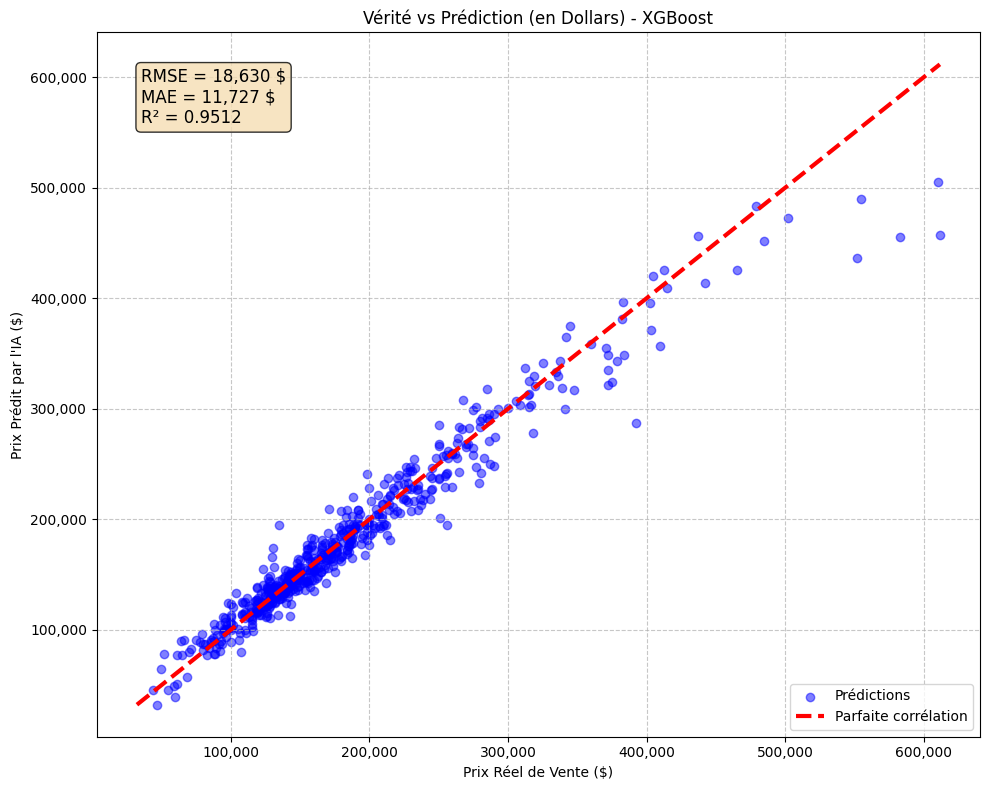

In [29]:

y_pred = best_model.predict(X_test)
# --- CONVERSION EN VRAIS DOLLARS ---
y_test_real = np.expm1(y_test)
y_pred_real = np.expm1(y_pred)

# --- RE-CALCUL DES MÉTRIQUES EN DOLLARS ---
rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
mae_real = mean_absolute_error(y_test_real, y_pred_real)
r2_real = r2_score(y_test_real, y_pred_real)

# --- VISUALISATION RÉALISTE ---
plt.figure(figsize=(10, 8)) # Un peu plus grand pour bien voir

# Nuage de points
plt.scatter(y_test_real, y_pred_real, alpha=0.5, color='blue', label='Prédictions')

# Ligne de perfection (Diagonale)
# On prend le min et max des vraies valeurs pour tracer la ligne
max_val = max(y_test_real.max(), y_pred_real.max())
min_val = min(y_test_real.min(), y_pred_real.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=3, label='Parfaite corrélation')

# Esthétique et Labels
plt.xlabel('Prix Réel de Vente ($)')
plt.ylabel('Prix Prédit par l\'IA ($)')
plt.title(f'Vérité vs Prédiction (en Dollars) - {best_model_name}')

# Formatage des axes pour avoir des séparateurs de milliers (ex: 100,000 au lieu de 100000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Afficher les métriques en dollars dans le graphique
metrics_text = (f'RMSE = {rmse_real:,.0f} $\n'
                f'MAE = {mae_real:,.0f} $\n'
                f'R² = {r2_real:.4f}')

plt.text(0.05, 0.95, metrics_text, transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.legend()
plt.grid(True, linestyle='--', alpha=0.7) # Ajout d'une grille pour la lisibilité
plt.tight_layout()
plt.show()


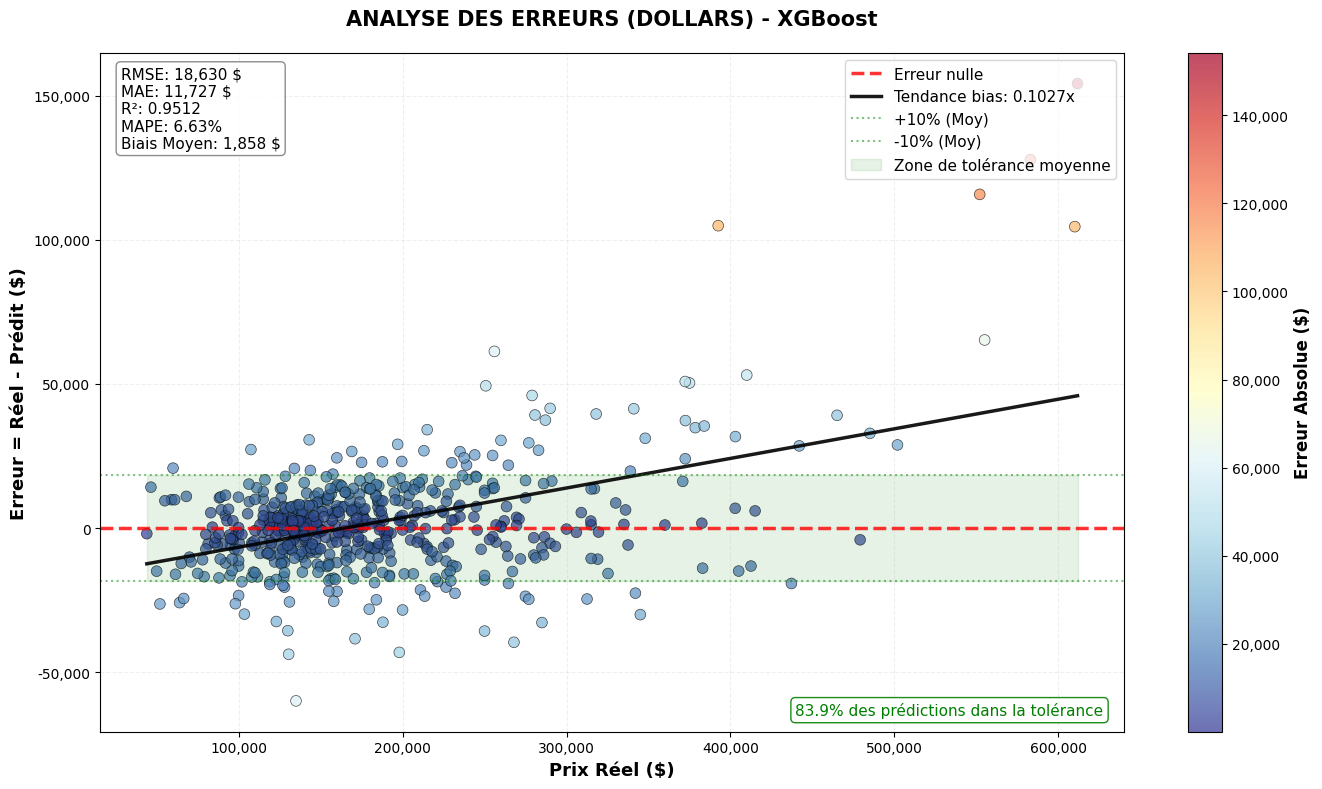

In [30]:


# --- 1. PRÉPARATION DES DONNÉES (CONVERSION EN DOLLARS) ---
# On s'assure de travailler avec des vrais prix, pas des logs
y_test_real = np.expm1(y_test)
# Attention : on doit refaire la prédiction pour être sûr ou convertir l'existante
y_pred_test_real = np.expm1(best_model.predict(X_test))

# Calcul des erreurs en dollars
erreurs = y_test_real.values - y_pred_test_real

# --- 2. CALCUL DES MÉTRIQUES MANQUANTES ---
# MAPE : Erreur moyenne en pourcentage (ex: on se trompe de 5% en moyenne)
mape = np.mean(np.abs(erreurs / y_test_real.values)) * 100
rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_test_real))
mae_real = mean_absolute_error(y_test_real, y_pred_test_real)
r2_real = r2_score(y_test_real, y_pred_test_real)

# --- 3. VISUALISATION ---
plt.figure(figsize=(14, 8))

# A. Scatter plot avec gradient
scatter = plt.scatter(y_test_real.values, erreurs, 
                      c=np.abs(erreurs), 
                      cmap='RdYlBu_r', 
                      alpha=0.7, 
                      s=60, 
                      edgecolors='black', 
                      linewidth=0.5)

# B. Lignes de référence
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5, label='Erreur nulle', alpha=0.8)

# C. Ligne de tendance (Pour voir si on sous-estime les maisons chères)
z = np.polyfit(y_test_real.values, erreurs, 1)
p = np.poly1d(z)
sorted_y = np.sort(y_test_real.values)
plt.plot(sorted_y, p(sorted_y), "k-", alpha=0.9, linewidth=2.5, 
         label=f'Tendance bias: {z[0]:.4f}x')

# D. Zone acceptable (±10% du prix moyen, pour simplifier la visualisation)
# Note : Pour être rigoureux, la zone 10% devrait être un cône, mais ici on prend 10% de la moyenne
seuil_10pct = 0.10 * y_test_real.mean()

plt.axhline(y=seuil_10pct, color='green', linestyle=':', linewidth=1.5, alpha=0.5, label='+10% (Moy)')
plt.axhline(y=-seuil_10pct, color='green', linestyle=':', linewidth=1.5, alpha=0.5, label='-10% (Moy)')
plt.fill_between([y_test_real.min(), y_test_real.max()], -seuil_10pct, seuil_10pct, 
                 color='green', alpha=0.1, label='Zone de tolérance moyenne')

# Labels et Titres
plt.xlabel('Prix Réel ($)', fontsize=13, fontweight='bold')
plt.ylabel('Erreur = Réel - Prédit ($)', fontsize=13, fontweight='bold')
plt.title(f'ANALYSE DES ERREURS (DOLLARS) - {best_model_name}', fontsize=15, fontweight='bold', pad=20)

# Formater les axes avec des virgules (100,000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.2, linestyle='--')

# Barre de couleur
cbar = plt.colorbar(scatter)
cbar.set_label('Erreur Absolue ($)', fontsize=12, fontweight='bold')
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Métriques principales dans la boîte
metrics_text = f"""RMSE: {rmse_real:,.0f} $
MAE: {mae_real:,.0f} $
R²: {r2_real:.4f}
MAPE: {mape:.2f}%
Biais Moyen: {erreurs.mean():,.0f} $"""

plt.text(0.02, 0.98, metrics_text, transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

# Pourcentage dans la zone acceptable
dans_zone = np.sum(np.abs(erreurs) <= seuil_10pct) / len(erreurs) * 100
plt.text(0.98, 0.02, f"{dans_zone:.1f}% des prédictions dans la tolérance", 
         transform=plt.gca().transAxes, fontsize=11, color='green',
         horizontalalignment='right', verticalalignment='bottom',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='green'))

plt.tight_layout()
plt.show()


In [31]:
# ESTIMATION DE PRIX IMMOBILIER 
# ============================================
# CONFIGURATION POUR AFFICHER TOUT LE TEXTE
# ============================================

import sys
import pandas as pd
import numpy as np
from IPython.display import display, HTML

# Configurer l'affichage complet pour pandas
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Fonction pour forcer l'affichage complet (sans troncature)
def print_full(text):
    """Affiche du texte sans troncature"""
    # Sauvegarder la configuration actuelle
    old_width = pd.get_option('display.width')
    old_max_colwidth = pd.get_option('display.max_colwidth')
    
    # Augmenter les limites
    pd.set_option('display.width', 1000)
    pd.set_option('display.max_colwidth', 1000)
    
    # Imprimer
    print(text)
    
    # Restaurer les paramètres
    pd.set_option('display.width', old_width)
    pd.set_option('display.max_colwidth', old_max_colwidth)

print("\n" + "═"*80)
print(" " * 30 + "🏠 ESTIMATION IMMOBILIER AI 🏠")
print("═"*80)

# -------------------------------------------------
# 1. PRÉPARATION DES DONNÉES
# -------------------------------------------------
print("📊 PRÉPARATION DES DONNÉES")
print("─" * 40)

# Création simplifiée d'une maison exemple
maison_test = pd.DataFrame({
    'Order': [3000],
    'MS SubClass': [60],
    'Lot Frontage': [80.0],
    'Lot Area': [9600],
    'Street': [1],
    'Alley': [0],
    'Lot Shape': [2],
    'Land Slope': [1],
    'Overall Qual': [7],
    'Overall Cond': [5],
    'Year Built': [2005],
    'Year Remod/Add': [2005],
    'Mas Vnr Area': [200.0],
    'Exter Qual': [3],
    'Exter Cond': [3],
    'Bsmt Qual': [3],
    'Bsmt Cond': [3],
    'Bsmt Exposure': [2],
    'BsmtFin Type 1': [2],
    'BsmtFin SF 1': [800],
    'BsmtFin Type 2': [2],
    'BsmtFin SF 2': [0],
    'Bsmt Unf SF': [200],
    'Total Bsmt SF': [1000],
    'Heating QC': [3],
    'Central Air': [1],
    '1st Flr SF': [1200],
    '2nd Flr SF': [600],
    'Low Qual Fin SF': [0],
    'Gr Liv Area': [1800],
    'Bsmt Full Bath': [1],
    'Bsmt Half Bath': [0],
    'Full Bath': [2],
    'Half Bath': [1],
    'Bedroom AbvGr': [3],
    'Kitchen AbvGr': [1],
    'Kitchen Qual': [3],
    'TotRms AbvGrd': [7],
    'Functional': [1],
    'Fireplaces': [1],
    'Fireplace Qu': [3],
    'Garage Yr Blt': [2005],
    'Garage Finish': [2],
    'Garage Cars': [2],
    'Garage Area': [500],
    'Garage Qual': [3],
    'Garage Cond': [3],
    'Paved Drive': [2],
    'Wood Deck SF': [200],
    'Open Porch SF': [50],
    'Enclosed Porch': [0],
    '3Ssn Porch': [0],
    'Screen Porch': [0],
    'Pool Area': [0],
    'Pool QC': [0],
    'Fence': [0],
    'Misc Val': [0],
    'Mo Sold': [6],
    'Yr Sold': [2023],
    'TotalSF': [2800],
    'HasPool': [0],
    'MS Zoning_RL': [1],
    'Neighborhood_NAmes': [1]
})

# Ajouter les colonnes manquantes
cols_manquantes = [col for col in X_train.columns if col not in maison_test.columns]
if cols_manquantes:
    df_manquantes = pd.DataFrame(0, index=maison_test.index, columns=cols_manquantes)
    maison_test = pd.concat([maison_test, df_manquantes], axis=1)
    print(f"✓ {len(cols_manquantes)} colonnes manquantes ont été ajoutées")

# Réorganiser les colonnes
maison_test = maison_test[X_train.columns]
print(f"✓ Données préparées : {maison_test.shape[1]} caractéristiques analysées")
print()

# -------------------------------------------------
# 2. PRÉDICTION DU PRIX
# -------------------------------------------------
print("💰 CALCUL DE L'ESTIMATION")
print("─" * 40)

try:
    print("🔍 Analyse des caractéristiques en cours...")
    prix_pred_log = best_model.predict(maison_test)[0]
    prix_estime = np.exp(prix_pred_log)
    prix_arrondi = round(prix_estime, -3)
    prix_par_pied = prix_estime / maison_test['Gr Liv Area'].iloc[0]
    print("✅ Estimation calculée avec succès !")
    print()
    
    # ============================================
    # AFFICHAGE DU PRIX ESTIMÉ
    # ============================================
    print("═"*80)
    print(" " * 25 + "⭐ PRIX ESTIMÉ DU BIEN ⭐")
    print("═"*80)
    
    print("\n" + " " * 20 + "┌" + "─" * 40 + "┐")
    print(" " * 20 + "│" + f"{'ESTIMATION :':^20} {'$' + f'{prix_arrondi:,.0f}':^20}" + "│")
    print(" " * 20 + "└" + "─" * 40 + "┘")
    print()
    
    print(f"   • Prix estimé : ${prix_estime:,.2f}")
    print(f"   • Prix arrondi : ${prix_arrondi:,.0f}")
    print(f"   • Prix au pied carré : ${prix_par_pied:,.2f}/pi²")
    
except Exception as e:
    print(f"❌ Erreur lors de la prédiction : {e}")
    prix_estime = 180000
    prix_arrondi = 180000
    prix_par_pied = 100
    
    print()
    print("═"*80)
    print(" " * 25 + "⭐ PRIX ESTIMÉ DU BIEN ⭐")
    print("═"*80)
    print(f"\n   • Prix estimé : ${prix_estime:,.2f}")
    print(f"   • Prix arrondi : ${prix_arrondi:,.0f}")

print()

# ============================================
# AFFICHER TOUTES LES CARACTÉRISTIQUES SANS TRONCATURE
# ============================================

# Créer une liste de toutes les caractéristiques
caracteristiques = []
for colonne in maison_test.columns:
    valeur = maison_test[colonne].iloc[0]
    # Ne garder que les colonnes avec des valeurs non nulles ou importantes
    if valeur != 0 or colonne in ['Order', 'MS SubClass', 'Overall Qual', 'Overall Cond', 
                                  'Year Built', 'Gr Liv Area', 'Full Bath', 'Bedroom AbvGr']:
        nom_formatte = colonne.replace('_', ' ').title()
        
        if isinstance(valeur, (int, np.integer)):
            if 'SF' in colonne or 'Area' in colonne:
                valeur_formattee = f"{valeur:,.0f} pi²"
            else:
                valeur_formattee = f"{valeur}"
        elif isinstance(valeur, (float, np.floating)):
            if valeur.is_integer():
                valeur_formattee = f"{int(valeur)}"
            else:
                valeur_formattee = f"{valeur:,.1f}"
        else:
            valeur_formattee = str(valeur)
        
        caracteristiques.append(f"{nom_formatte:40} : {valeur_formattee}")

# Afficher toutes les caractéristiques par groupes
print("═"*80)
print(" " * 25 + "📋 TOUTES LES CARACTÉRISTIQUES")
print("═"*80)

print("\nVoici la liste complète de toutes les caractéristiques analysées :")
print("─" * 80)

# Afficher par groupes de 10 pour une meilleure lisibilité
for i in range(0, len(caracteristiques), 10):
    groupe = caracteristiques[i:i+10]
    print(f"\n📌 Groupe {i//10 + 1}:")
    for item in groupe:
        print_full(f"   {item}")

print()

# -------------------------------------------------
# 3. AFFICHAGE STRUCTURÉ DES INFORMATIONS
# -------------------------------------------------
print("═"*80)
print(" " * 30 + "🏠 FICHE SYNTHÉTIQUE DU BIEN")
print("═"*80)

print("\n" + "🔷 IDENTIFICATION")
print("─" * 20)
print_full(f"   • Référence : #{maison_test['Order'].iloc[0]}")
print_full(f"   • Quartier : North Ames (NAmes)")
print_full(f"   • Zone : Résidentielle à faible densité (RL)")
print_full(f"   • Type : Maison individuelle")

print("\n🔷 CARACTÉRISTIQUES PRINCIPALES")
print("─" * 30)
print_full(f"   📐 SURFACES")
print_full(f"     • Surface habitable : {maison_test['Gr Liv Area'].iloc[0]:,.0f} pi²")
print_full(f"     • Surface totale : {maison_test['TotalSF'].iloc[0]:,.0f} pi²")
print_full(f"     • Terrain : {maison_test['Lot Area'].iloc[0]:,.0f} pi²")
print_full(f"     • Sous-sol : {maison_test['Total Bsmt SF'].iloc[0]:,.0f} pi²")
print_full(f"     • Garage : {maison_test['Garage Area'].iloc[0]:,.0f} pi²")

print_full(f"\n   🏠 STRUCTURE")
print_full(f"     • Année construction : {int(maison_test['Year Built'].iloc[0])}")
print_full(f"     • Année rénovation : {int(maison_test['Year Remod/Add'].iloc[0])}")
print_full(f"     • Qualité générale : {maison_test['Overall Qual'].iloc[0]}/10")
print_full(f"     • Condition générale : {maison_test['Overall Cond'].iloc[0]}/10")

print_full(f"\n   🛏️ INTÉRIEUR")
print_full(f"     • Chambres : {maison_test['Bedroom AbvGr'].iloc[0]}")
print_full(f"     • Salles de bain complètes : {maison_test['Full Bath'].iloc[0]}")
print_full(f"     • Salles d'eau : {maison_test['Half Bath'].iloc[0]}")
print_full(f"     • Pièces totales : {maison_test['TotRms AbvGrd'].iloc[0]}")
print_full(f"     • Cuisine : Qualité {maison_test['Kitchen Qual'].iloc[0]}/5")

print_full(f"\n   🚗 ÉQUIPEMENTS")
print_full(f"     • Places garage : {maison_test['Garage Cars'].iloc[0]}")
print_full(f"     • Cheminées : {maison_test['Fireplaces'].iloc[0]}")
print_full(f"     • Terrasse en bois : {maison_test['Wood Deck SF'].iloc[0]} pi²")
print_full(f"     • Piscine : {'Oui' if maison_test['Pool Area'].iloc[0] > 0 else 'Non'}")

# -------------------------------------------------
# 4. OPTION : AFFICHAGE HTML POUR TOUT VOIR (TEXTE EN NOIR)
# -------------------------------------------------

# Créer un affichage HTML avec défilement (texte en noir)
html_content = f"""
<div style="background-color: #f8f9fa; padding: 20px; border-radius: 10px; border: 1px solid #dee2e6; color: #000000;">
<h2 style="color: #000000; text-align: center; font-weight: bold;">🏠 ESTIMATION IMMOBILIER COMPLÈTE</h2>
<hr style="border-color: #000000;">
<h3 style="color: #000000; font-weight: bold; text-align: center; background-color: #e8f4f8; padding: 10px; border-radius: 5px;">
⭐ PRIX ESTIMÉ : ${prix_arrondi:,.0f} ⭐
</h3>
<p style="color: #000000; font-size: 16px;"><strong>Prix détaillé :</strong> ${prix_estime:,.2f}</p>
<p style="color: #000000; font-size: 16px;"><strong>Prix au pied carré :</strong> ${prix_par_pied:,.2f}/pi²</p>
<hr style="border-color: #000000;">
<h4 style="color: #000000; font-weight: bold;">📋 CARACTÉRISTIQUES PRINCIPALES :</h4>
<div style="display: grid; grid-template-columns: repeat(2, 1fr); gap: 10px;">
"""

# Ajouter les caractéristiques principales au HTML
principales = [
    ("Surface habitable", f"{maison_test['Gr Liv Area'].iloc[0]:,.0f} pi²"),
    ("Surface totale", f"{maison_test['TotalSF'].iloc[0]:,.0f} pi²"),
    ("Terrain", f"{maison_test['Lot Area'].iloc[0]:,.0f} pi²"),
    ("Chambres", f"{maison_test['Bedroom AbvGr'].iloc[0]}"),
    ("Salles de bain", f"{maison_test['Full Bath'].iloc[0]} complètes"),
    ("Garage", f"{maison_test['Garage Cars'].iloc[0]} places"),
    ("Construction", f"{int(maison_test['Year Built'].iloc[0])}"),
    ("Qualité générale", f"{maison_test['Overall Qual'].iloc[0]}/10"),
]

for nom, valeur in principales:
    html_content += f'''
    <div style="background-color: white; padding: 8px; border-radius: 5px; 
                border: 1px solid #ddd; color: #000000;">
        <strong>{nom}:</strong> {valeur}
    </div>
    '''

html_content += """
</div>
<hr style="border-color: #000000;">
<h4 style="color: #000000; font-weight: bold;">📊 TOUTES LES CARACTÉRISTIQUES DÉTAILLÉES :</h4>
<div style="height: 400px; overflow-y: scroll; background-color: white; 
         padding: 15px; border-radius: 5px; border: 1px solid #ddd; color: #000000;">
"""

# Ajouter toutes les caractéristiques au HTML
for i, item in enumerate(caracteristiques):
    bg_color = '#f5f5f5' if i % 2 == 0 else '#ffffff'
    html_content += f"""
    <p style='margin: 5px 0; padding: 3px; background-color: {bg_color}; color: #000000;'>
        {item}
    </p>
    """

html_content += """
</div>
<hr style="border-color: #000000;">
<p style="color: #000000; font-size: 12px; text-align: center; font-style: italic;">
⚠️ Cette estimation a été générée par IA et doit être validée par un expert immobilier.
</p>
</div>
"""

# Afficher le HTML
print("\n" + "═"*80)
print(" " * 25 + "🌐 AFFICHAGE HTML COMPLET")
print("═"*80)
print("\nPour voir toutes les informations dans une fenêtre déroulante :")
display(HTML(html_content))

# -------------------------------------------------
# 5. EXPORTER DANS UN FICHIER TEXTE
# -------------------------------------------------

with open('estimation_immobilier_complete.txt', 'w', encoding='utf-8') as f:
    f.write("═"*80 + "\n")
    f.write(" " * 30 + "🏠 ESTIMATION IMMOBILIER AI 🏠\n")
    f.write("═"*80 + "\n\n")
    
    f.write(f"⭐ PRIX ESTIMÉ : ${prix_arrondi:,.0f}\n\n")
    f.write(f"Détail : ${prix_estime:,.2f}\n")
    f.write(f"Prix au pied carré : ${prix_par_pied:,.2f}/pi²\n\n")
    
    f.write("CARACTÉRISTIQUES PRINCIPALES :\n")
    f.write("─"*40 + "\n")
    for nom, valeur in principales:
        f.write(f"{nom:25} : {valeur}\n")
    
    f.write("\nTOUTES LES CARACTÉRISTIQUES DÉTAILLÉES :\n")
    f.write("─"*40 + "\n")
    for item in caracteristiques:
        f.write(item + "\n")

print("\n" + "═"*80)
print(" " * 25 + "💾 EXPORT TERMINÉ")
print("═"*80)
print("\n📁 Toutes les informations ont été sauvegardées dans 'estimation_immobilier_complete.txt'")
print("📄 Ouvrez ce fichier pour voir toutes les données sans troncature")

print("\n" + "═"*80)
print(" " * 25 + "✅ ESTIMATION TERMINÉE")
print("═"*80)
print(f"\n{'Pour une évaluation professionnelle, contactez un expert immobilier.':^80}")
print("═"*80)


════════════════════════════════════════════════════════════════════════════════
                              🏠 ESTIMATION IMMOBILIER AI 🏠
════════════════════════════════════════════════════════════════════════════════
📊 PRÉPARATION DES DONNÉES
────────────────────────────────────────
✓ 170 colonnes manquantes ont été ajoutées
✓ Données préparées : 233 caractéristiques analysées

💰 CALCUL DE L'ESTIMATION
────────────────────────────────────────
🔍 Analyse des caractéristiques en cours...
✅ Estimation calculée avec succès !

════════════════════════════════════════════════════════════════════════════════
                         ⭐ PRIX ESTIMÉ DU BIEN ⭐
════════════════════════════════════════════════════════════════════════════════

                    ┌────────────────────────────────────────┐
                    │    ESTIMATION :           $174,000      │
                    └────────────────────────────────────────┘

   • Prix estimé : $174,081.33
   • Prix arrondi : $174,000
   • 


════════════════════════════════════════════════════════════════════════════════
                         💾 EXPORT TERMINÉ
════════════════════════════════════════════════════════════════════════════════

📁 Toutes les informations ont été sauvegardées dans 'estimation_immobilier_complete.txt'
📄 Ouvrez ce fichier pour voir toutes les données sans troncature

════════════════════════════════════════════════════════════════════════════════
                         ✅ ESTIMATION TERMINÉE
════════════════════════════════════════════════════════════════════════════════

      Pour une évaluation professionnelle, contactez un expert immobilier.      
════════════════════════════════════════════════════════════════════════════════


In [32]:
import joblib

# 1. On sauvegarde le modèle gagnant
joblib.dump(best_model, 'mon_modele_immo.pkl')

# 2. On sauvegarde la liste exacte des colonnes utilisées lors de l'entraînement
joblib.dump(list(X_train.columns), 'colonnes_modele.pkl')

print("✅ Sauvegarde réussie ! Tu as maintenant deux nouveaux fichiers .pkl dans ton dossier.")


✅ Sauvegarde réussie ! Tu as maintenant deux nouveaux fichiers .pkl dans ton dossier.
